# Step 3: Classification - Predicting Late Delivery

**Goal:** when a customer places an order, predict whether it will be **delivered late** (`Late_delivery_risk` = 1).

### What makes my approach different
1. **No cheating (no data leakage).** I only use information available *when the order is placed*. Real shipping days and delivery status are never used as inputs.
2. **Realistic testing.** I train on older orders and test on newer orders (a **time-based split**), the same way the model would be used in real life.
3. **One row per order.** All items in an order share the same outcome, so I predict at the **order level**. Items of one order can never end up in both training and testing.
4. **I know the target to beat.** From Step 2, the best honest accuracy possible is about **72%**. I compare every model against that.

### Models (from simple to complex)
| Model | Why |
|---|---|
| Baseline: always say "late" | The minimum any model must beat |
| Business rule from EDA | What a smart analyst could do without ML |
| Logistic Regression | Simple, explainable model |
| Logistic Regression + engineered feature | Shows the value of feature engineering |
| Random Forest | Ensemble of decision trees (bagging) |
| XGBoost | Ensemble of boosted trees (boosting), tuned with cross-validation |

### How I evaluate
Missing a late order (the customer is unhappy, with no warning) is worse than a false alarm. So **recall for late orders** is my main metric. I also report precision, F1, accuracy, ROC-AUC, PR-AUC and confusion matrices.

## 1. Setup

In [1]:
import sys, os, subprocess, time
IN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data
Same loader as Step 2: it uses the cleaned files from Step 1 if they exist, otherwise it rebuilds them from the raw data.

In [2]:
def find_processed_dir():
    candidates = ["/content/drive/MyDrive/dataco-final-project/processed",
                  "/content/dataco-final-project/processed",
                  os.path.join("..", "data", "processed")]
    if IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
    for c in candidates:
        if os.path.exists(os.path.join(c, "orders_clean.parquet")):
            return c
    return None

def rebuild_orders_from_raw():
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    data_dir = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
    raw = pd.read_csv(os.path.join(data_dir, "DataCoSupplyChainDataset.csv"), encoding="latin-1")
    raw["order_date"] = pd.to_datetime(raw["order date (DateOrders)"])
    orders = (raw.groupby("Order Id")
                 .agg(order_date=("order_date", "first"),
                      customer_segment=("Customer Segment", "first"), market=("Market", "first"),
                      order_region=("Order Region", "first"), order_country=("Order Country", "first"),
                      shipping_mode=("Shipping Mode", "first"), payment_type=("Type", "first"),
                      days_scheduled=("Days for shipment (scheduled)", "first"),
                      days_real=("Days for shipping (real)", "first"),
                      late=("Late_delivery_risk", "first"),
                      delivery_status=("Delivery Status", "first"),
                      n_items=("Order Item Id", "count"), total_quantity=("Order Item Quantity", "sum"),
                      gross_sales=("Sales", "sum"), total_discount=("Order Item Discount", "sum"),
                      n_categories=("Category Name", "nunique"))
                 .reset_index().rename(columns={"Order Id": "order_id"}))
    orders["is_canceled"] = orders["delivery_status"].eq("Shipping canceled")
    orders["avg_discount_rate"] = orders["total_discount"] / orders["gross_sales"]
    return orders

proc = find_processed_dir()
if proc:
    orders = pd.read_parquet(os.path.join(proc, "orders_clean.parquet"))
    print("Loaded cleaned orders from:", proc)
else:
    print("Cleaned files not found - rebuilding from raw data (about 1 minute)...")
    orders = rebuild_orders_from_raw()

# Only shipped orders can be late or on time
df = orders[~orders["is_canceled"]].copy().sort_values("order_date").reset_index(drop=True)
print(f"Shipped orders: {len(df):,}   Late share: {df['late'].mean():.1%}")

Loaded cleaned orders from: ..\data\processed
Shipped orders: 62,897   Late share: 57.3%


## 3. Choose the input features (only what is known at order time)
I also create the feature I discovered in Step 2: **Same Day order placed after noon**.

In [3]:
df["order_hour"] = df["order_date"].dt.hour
df["order_month"] = df["order_date"].dt.month
df["order_weekday"] = df["order_date"].dt.day_name()
df["after_noon"] = (df["order_hour"] >= 12).astype(int)
df["same_day_after_noon"] = ((df["shipping_mode"] == "Same Day") & (df["after_noon"] == 1)).astype(int)

categorical = ["shipping_mode", "market", "order_region", "customer_segment", "payment_type", "order_weekday"]
numeric = ["order_hour", "order_month", "n_items", "total_quantity", "gross_sales", "avg_discount_rate", "n_categories"]
engineered = ["after_noon", "same_day_after_noon"]
target = "late"

# Columns I deliberately DO NOT use, because they are only known after delivery
leakage_columns = ["days_real", "delivery_status", "delay_gap", "order_status", "profit", "profit_margin"]
print("Inputs:", categorical + numeric)
print("Never used as inputs:", leakage_columns)

Inputs: ['shipping_mode', 'market', 'order_region', 'customer_segment', 'payment_type', 'order_weekday', 'order_hour', 'order_month', 'n_items', 'total_quantity', 'gross_sales', 'avg_discount_rate', 'n_categories']
Never used as inputs: ['days_real', 'delivery_status', 'delay_gap', 'order_status', 'profit', 'profit_margin']


## 4. Time-based train/test split
- **Training set:** orders from Jan 2015 to Jun 2017 (2.5 years)
- **Test set:** orders from Jul 2017 to Jan 2018 (the "future")

The test set is used **only once**, at the end. For tuning I use cross-validation *inside* the training set, also respecting time order (`TimeSeriesSplit`).

In [4]:
cutoff = pd.Timestamp("2017-07-01")
train = df[df["order_date"] < cutoff]
test = df[df["order_date"] >= cutoff]

print(f"Train: {len(train):,} orders  ({train['order_date'].min().date()} to {train['order_date'].max().date()})  late = {train[target].mean():.1%}")
print(f"Test:  {len(test):,} orders  ({test['order_date'].min().date()} to {test['order_date'].max().date()})  late = {test[target].mean():.1%}")

y_train, y_test = train[target], test[target]
cv = TimeSeriesSplit(n_splits=5)

Train: 49,826 orders  (2015-01-01 to 2017-06-30)  late = 57.2%
Test:  13,071 orders  (2017-07-01 to 2018-01-31)  late = 57.6%


## 5. Preprocessing pipeline
- **Categories** (shipping mode, region, …) are turned into 0/1 columns with **one-hot encoding**. Label encoding (Brazil = 1, Canada = 2, …) would wrongly suggest an order between categories.
- **Numbers** are **standardized** (mean 0, std 1), which Logistic Regression needs.
- Everything is wrapped in a `Pipeline`, so the scaler and encoder learn **only from training data**.

In [5]:
def make_preprocessor(cat_cols, num_cols):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])

base_features = categorical + numeric
eng_features = categorical + numeric + engineered

## 6. Baselines
Before any machine learning, two simple references:
1. **Always predict "late"** (the majority class).
2. **The business rule from Step 2:** First Class → late, Second Class → late, Standard → on time, Same Day → late only if ordered after noon.

In [6]:
def evaluate(name, y_true, y_pred, y_prob=None):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_late": precision_score(y_true, y_pred, zero_division=0),
        "recall_late": recall_score(y_true, y_pred),
        "f1_late": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan,
        "pr_auc": average_precision_score(y_true, y_prob) if y_prob is not None else np.nan,
    }

results, predictions = [], {}

dummy = DummyClassifier(strategy="most_frequent").fit(train[base_features], y_train)
pred = dummy.predict(test[base_features])
results.append(evaluate("Baseline: always 'late'", y_test, pred))
predictions["Baseline: always 'late'"] = pred

def business_rule(d):
    return np.select(
        [d["shipping_mode"].isin(["First Class", "Second Class"]),
         d["shipping_mode"] == "Same Day"],
        [1, d["after_noon"]],
        default=0)

pred = business_rule(test)
results.append(evaluate("Business rule (from EDA)", y_test, pred))
predictions["Business rule (from EDA)"] = pred
pd.DataFrame(results).round(3)

,model,accuracy,precision_late,recall_late,f1_late,roc_auc,pr_auc
0,Baseline: always 'late',0.576,0.576,1.000,0.731,NaN,NaN
1,Business rule (from EDA),0.726,0.898,0.592,0.713,NaN,NaN


The business rule is the "ceiling" from Step 2, written as simple if/else logic. Now let's see whether machine learning can learn this by itself, or do even better.

## 7. Logistic Regression
I use `class_weight="balanced"` so the model doesn't simply favour the bigger class.

In [7]:
models = {}

models["Logistic Regression"] = (Pipeline([
    ("prep", make_preprocessor(categorical, numeric)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
]), base_features)

models["Logistic Regression + engineered feature"] = (Pipeline([
    ("prep", make_preprocessor(categorical, numeric + engineered)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
]), eng_features)

## 8. Random Forest (bagging ensemble)
Many decision trees, each trained on a random sample; the trees vote. Trees can learn interactions like "Same Day **and** after noon" on their own.

In [8]:
models["Random Forest"] = (Pipeline([
    ("prep", make_preprocessor(categorical, numeric)),
    ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced",
                                   n_jobs=-1, random_state=RANDOM_STATE)),
]), base_features)

## 9. XGBoost (boosting ensemble) with hyperparameter tuning
Boosting builds trees one after another, and each new tree fixes the mistakes of the previous ones.
I tune a few settings with `RandomizedSearchCV` and time-ordered cross-validation on the **training set only**.

In [9]:
xgb_pipe = Pipeline([
    ("prep", make_preprocessor(categorical, numeric)),
    ("clf", XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE,
                          scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum())),
])
param_grid = {
    "clf__n_estimators": [100, 200, 400],
    "clf__max_depth": [2, 3, 4, 6],
    "clf__learning_rate": [0.03, 0.1, 0.2],
    "clf__subsample": [0.7, 0.9, 1.0],
    "clf__min_child_weight": [1, 5, 20],
}
search = RandomizedSearchCV(xgb_pipe, param_grid, n_iter=12, scoring="roc_auc", cv=cv,
                            random_state=RANDOM_STATE, n_jobs=1)
t0 = time.time()
search.fit(train[base_features], y_train)
print(f"Tuning took {time.time() - t0:.0f}s")
print("Best settings:", search.best_params_)
print(f"Best cross-validated ROC-AUC: {search.best_score_:.3f}")
models["XGBoost (tuned)"] = (search.best_estimator_, base_features)

Tuning took 84s
Best settings: {'clf__subsample': 0.7, 'clf__n_estimators': 400, 'clf__min_child_weight': 20, 'clf__max_depth': 2, 'clf__learning_rate': 0.1}
Best cross-validated ROC-AUC: 0.776


## 10. Cross-validation on the training set
Before touching the test set, I check how stable each model is across 5 time-ordered folds.

In [10]:
cv_rows = []
for name, (pipe, feats) in models.items():
    scores = cross_val_score(pipe, train[feats], y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_rows.append({"model": name, "cv_roc_auc_mean": scores.mean(), "cv_roc_auc_std": scores.std()})
pd.DataFrame(cv_rows).round(3)

,model,cv_roc_auc_mean,cv_roc_auc_std
0,Logistic Regression,0.744,0.003
1,Logistic Regression + engineered feature,0.774,0.003
2,Random Forest,0.772,0.002
3,XGBoost (tuned),0.776,0.002


**What I learned:** all models are very **stable** across the 5 time periods (std about 0.003), so the results don't depend on luck.
Plain Logistic Regression is clearly weaker (0.744). Adding my one engineered feature (Same Day after noon) lifts it to the level of the tree ensembles (about 0.775).

## 11. Final evaluation on the test set (future orders)

In [11]:
probas = {}
for name, (pipe, feats) in models.items():
    pipe.fit(train[feats], y_train)
    prob = pipe.predict_proba(test[feats])[:, 1]
    pred = (prob >= 0.5).astype(int)
    probas[name], predictions[name] = prob, pred
    results.append(evaluate(name, y_test, pred, prob))

results_df = pd.DataFrame(results).set_index("model")
results_df.round(3)

,accuracy,precision_late,recall_late,f1_late,roc_auc,pr_auc
model,,,,,,
Baseline: always 'late',0.576,0.576,1.000,0.731,NaN,NaN
Business rule (from EDA),0.726,0.898,0.592,0.713,NaN,NaN
Logistic Regression,0.696,0.890,0.539,0.671,0.753,0.842
Logistic Regression + engineered feature,0.726,0.898,0.592,0.713,0.781,0.860
Random Forest,0.726,0.898,0.592,0.713,0.780,0.860
XGBoost (tuned),0.726,0.898,0.592,0.713,0.779,0.860


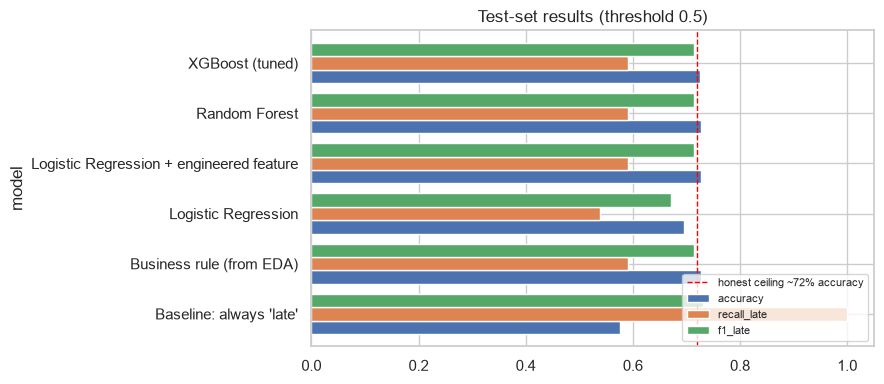

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_df = results_df[["accuracy", "recall_late", "f1_late"]]
plot_df.plot.barh(ax=ax, width=0.8)
ax.axvline(0.72, color="red", ls="--", lw=1, label="honest ceiling ~72% accuracy")
ax.set_xlim(0, 1.05); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Test-set results (threshold 0.5)")
plt.tight_layout(); plt.show()

**What I learned (main result):**
- Every model beats the "always late" baseline (57.6% accuracy).
- **Logistic Regression + engineered feature, Random Forest and tuned XGBoost all reach 72.6% accuracy (ROC-AUC about 0.78). That is exactly the business rule from my EDA, and exactly the 72% ceiling I calculated in Step 2.**
- Plain Logistic Regression is lower (69.6%) because a straight-line model can't discover the "Same Day **and** after noon" interaction on its own. Once I add that feature, it catches up. Feature engineering beat model complexity.
- The complex models **rediscovered the rule** but couldn't go beyond it, because the rest of the delay is random in this data (Step 2 showed actual days are spread evenly from 2 to 6).

### Confusion matrices

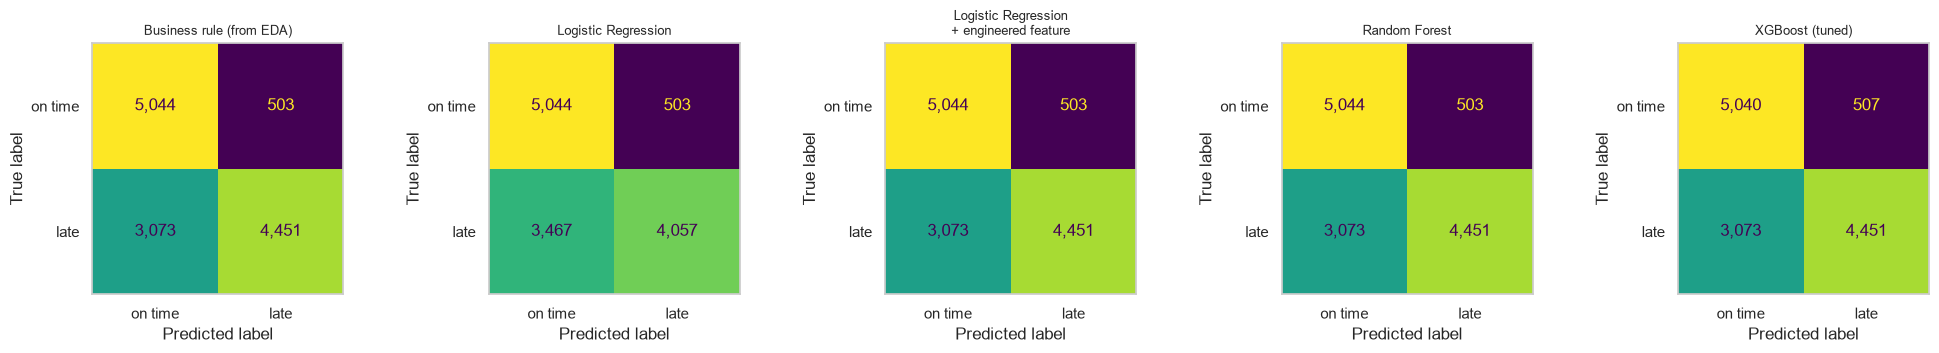

In [13]:
show = ["Business rule (from EDA)", "Logistic Regression", "Logistic Regression + engineered feature",
        "Random Forest", "XGBoost (tuned)"]
fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 3.6))
for ax, name in zip(axes, show):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predictions[name]),
                           display_labels=["on time", "late"]).plot(ax=ax, colorbar=False, values_format=",")
    ax.set_title(name.replace(" + ", "\n+ "), fontsize=9)
    ax.grid(False)
plt.tight_layout(); plt.show()

**How to read these:** top-right = on-time orders wrongly flagged as late (false alarms); bottom-left = late orders the model **missed**.
- The three good models make **almost exactly the same predictions** as the business rule.
- About **500 false alarms** are Second Class orders that happen to arrive on time (the 20% that aren't late).
- About **3,000 missed late orders** are Standard Class orders. Standard is late 40% of the time, so at the 0.5 threshold the model always says "on time" for them. That's why recall is only about 59%. I fix this in section 13 with a better threshold.

### ROC and Precision-Recall curves

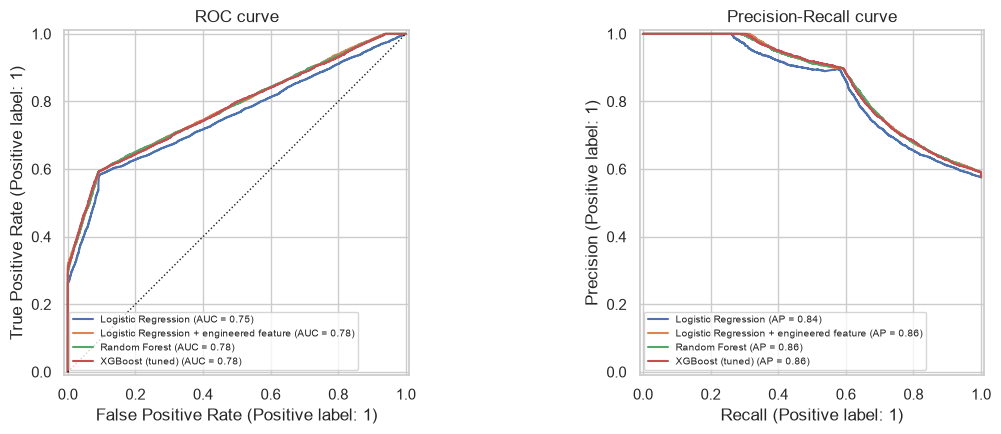

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, prob in probas.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set_title("ROC curve"); axes[1].set_title("Precision-Recall curve")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 12. Which features does the model rely on?
I use **permutation importance**: shuffle one column at a time and measure how much the ROC-AUC drops. A big drop means the model depends on that column.

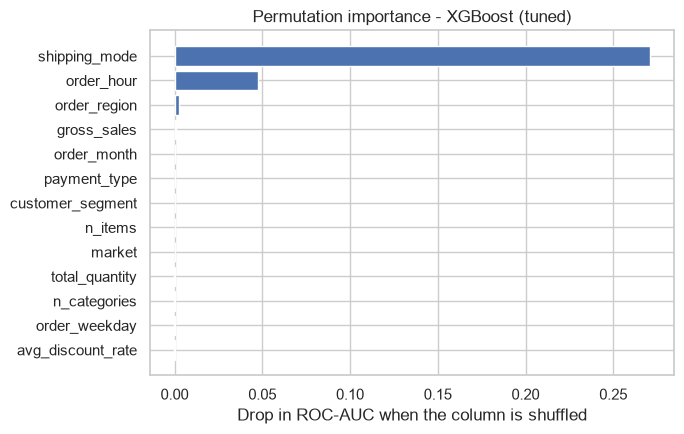

shipping_mode        0.2711
order_hour           0.0474
order_region         0.0023
gross_sales          0.0007
order_month          0.0005
payment_type         0.0003
customer_segment     0.0001
n_items              0.0000
market               0.0000
total_quantity      -0.0001
n_categories        -0.0001
order_weekday       -0.0003
avg_discount_rate   -0.0003
dtype: float64

In [15]:
best_name = "XGBoost (tuned)"
best_pipe, best_feats = models[best_name]
imp = permutation_importance(best_pipe, test[best_feats], y_test, scoring="roc_auc",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=best_feats).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.values, color="#4C72B0")
ax.set_title(f"Permutation importance - {best_name}")
ax.set_xlabel("Drop in ROC-AUC when the column is shuffled")
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(4)

**What I learned:** the model relies almost entirely on **shipping mode**, plus **order hour** (for the Same Day noon cut-off).
Shuffling region, market, customer segment, payment type, sales or discount changes almost nothing. This matches the statistical tests in Step 2: two different methods give the same answer.

## 13. Choosing the decision threshold with business costs
By default a model says "late" when the probability is ≥ 0.5. But the two mistakes don't cost the same:
- **Missed late order (false negative):** the customer is surprised and unhappy, may complain or leave. I assume a **cost of 5**.
- **False alarm (false positive):** we warn the customer or expedite the order for nothing. I assume a **cost of 1**.

I pick the threshold with the **lowest total cost**, using the last part of the *training* period (not the test set), and then apply it to the test set.

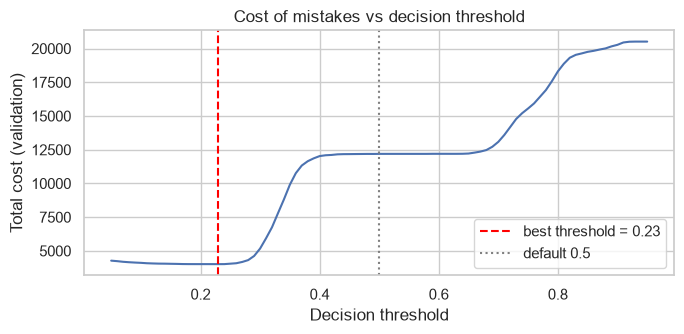

,accuracy,precision_late,recall_late,f1_late,roc_auc,pr_auc,total_cost
model,,,,,,,
XGBoost (tuned) @ 0.5,0.726,0.898,0.592,0.713,0.779,0.86,15872
XGBoost (tuned) @ 0.23,0.601,0.591,0.999,0.743,0.779,0.86,5233


In [16]:
COST_MISSED_LATE, COST_FALSE_ALARM = 5, 1

val_cut = pd.Timestamp("2017-01-01")
fit_part, val_part = train[train["order_date"] < val_cut], train[train["order_date"] >= val_cut]
from sklearn.base import clone
threshold_model = clone(best_pipe).fit(fit_part[best_feats], fit_part[target])
val_prob = threshold_model.predict_proba(val_part[best_feats])[:, 1]

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
def total_cost(y_true, prob, t):
    pred = (prob >= t).astype(int)
    fn = ((pred == 0) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum()
    return COST_MISSED_LATE * fn + COST_FALSE_ALARM * fp

costs = [total_cost(val_part[target].values, val_prob, t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(thresholds, costs)
ax.axvline(best_t, color="red", ls="--", label=f"best threshold = {best_t}")
ax.axvline(0.5, color="grey", ls=":", label="default 0.5")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Total cost (validation)"); ax.legend()
ax.set_title("Cost of mistakes vs decision threshold")
plt.tight_layout(); plt.show()

test_prob = probas[best_name]
compare = pd.DataFrame([
    evaluate(f"{best_name} @ 0.5", y_test, (test_prob >= 0.5).astype(int), test_prob),
    evaluate(f"{best_name} @ {best_t}", y_test, (test_prob >= best_t).astype(int), test_prob),
]).set_index("model")
compare["total_cost"] = [total_cost(y_test.values, test_prob, 0.5), total_cost(y_test.values, test_prob, best_t)]
compare.round(3)

**What I learned:** the cost-based threshold (about 0.23) is much lower than 0.5. At that threshold the model also flags **Standard Class orders** (40% late) as "at risk".
- **Recall for late orders jumps from about 59% to almost 100%.** Almost no late order is missed.
- Precision drops (more false alarms), but with my assumed costs the **total cost of mistakes falls by about two-thirds** (15,872 → 5,233).
- **Business meaning:** if a missed late order costs much more than a warning, the company should warn on almost every order. In practice, that means fixing the promises (Step 2 recommendation) rather than predicting.

## 14. Can we trust the probabilities? (calibration)
If the model says "70% chance of being late", are about 70% of those orders actually late? A calibrated model lets the company **rank orders by risk**.

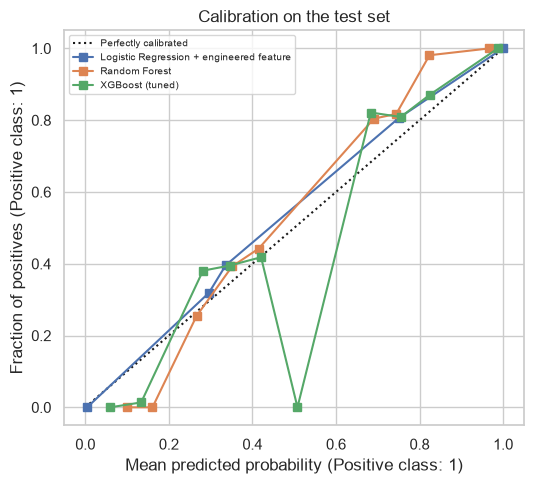

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name in ["Logistic Regression + engineered feature", "Random Forest", "XGBoost (tuned)"]:
    CalibrationDisplay.from_predictions(y_test, probas[name], n_bins=10, name=name, ax=ax)
ax.set_title("Calibration on the test set"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**What I learned:** the curves stay close to the diagonal, so the predicted probabilities are **trustworthy**. When the model says about 40% (Standard Class), about 40% are really late; when it says about 80% (Second Class), about 80% are late.
(The single XGBoost dip near 0.5 is a bin with very few orders, so I don't read much into it.)

## 15. Proof of leakage: what happens if we "cheat"?
Many public notebooks on this dataset report about 99% accuracy. To show why, I train the **same Random Forest**, but I also give it `days_real`, the actual shipping days, which you only know *after* delivery.

In [18]:
leaky_features = base_features + ["days_real"]
leaky_rf = Pipeline([
    ("prep", make_preprocessor(categorical, numeric + ["days_real"])),
    ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced",
                                   n_jobs=-1, random_state=RANDOM_STATE)),
]).fit(train[leaky_features], y_train)
leaky_prob = leaky_rf.predict_proba(test[leaky_features])[:, 1]

leak_compare = pd.DataFrame([
    evaluate("Random Forest - honest (order-time info only)", y_test, predictions["Random Forest"], probas["Random Forest"]),
    evaluate("Random Forest - LEAKY (uses actual shipping days)", y_test, (leaky_prob >= 0.5).astype(int), leaky_prob),
]).set_index("model")
leak_compare.round(3)

,accuracy,precision_late,recall_late,f1_late,roc_auc,pr_auc
model,,,,,,
Random Forest - honest (order-time info only),0.726,0.898,0.592,0.713,0.78,0.86
Random Forest - LEAKY (uses actual shipping days),1.000,1.000,1.000,1.000,1.00,1.00


The leaky model looks almost perfect, but it is useless in practice: it needs the actual shipping days, which you only know after the package has arrived. **This is why I don't report the 99% number.**

## 16. Summary of Step 3

| Model | Accuracy | Recall (late) | ROC-AUC |
|---|---|---|---|
| Baseline: always "late" | 57.6% | 100% | - |
| Business rule from EDA | 72.6% | 59.2% | - |
| Logistic Regression | 69.6% | 53.9% | 0.753 |
| Logistic Regression + engineered feature | **72.6%** | 59.2% | **0.781** |
| Random Forest | **72.6%** | 59.2% | 0.780 |
| XGBoost (tuned) | **72.6%** | 59.2% | 0.779 |
| XGBoost with cost-based threshold | 60.1% | **99.9%** | 0.779 |
| *LEAKY Random Forest (for reference only)* | *100%* | *100%* | *1.000* |

### Key takeaways
1. **The honest best is about 72.6% accuracy**, which matches the ceiling I calculated from the EDA. The leaky 100% is fake.
2. **Simple + smart beat complex.** Logistic Regression with one well-chosen feature performed as well as Random Forest and XGBoost.
3. **Shipping mode (and order hour for Same Day) explain the risk.** Region, customer and product don't.
4. **The threshold matters as much as the model.** With business costs, recall goes from 59% to almost 100%.
5. **Recommendation:** the most powerful fix isn't a better model, it's **realistic delivery promises**. If First Class promised 2 days, all of its "late" orders would become on time.

**Next:** Step 4, regression: predicting the **number of shipping days**.

The table below is the same summary, computed by the code:

In [19]:
final_table = results_df.copy()
final_table.loc["(for reference) LEAKY Random Forest"] = leak_compare.iloc[1]
final_table.round(3)

,accuracy,precision_late,recall_late,f1_late,roc_auc,pr_auc
model,,,,,,
Baseline: always 'late',0.576,0.576,1.000,0.731,NaN,NaN
Business rule (from EDA),0.726,0.898,0.592,0.713,NaN,NaN
Logistic Regression,0.696,0.890,0.539,0.671,0.753,0.842
Logistic Regression + engineered feature,0.726,0.898,0.592,0.713,0.781,0.860
Random Forest,0.726,0.898,0.592,0.713,0.780,0.860
XGBoost (tuned),0.726,0.898,0.592,0.713,0.779,0.860
(for reference) LEAKY Random Forest,1.000,1.000,1.000,1.000,1.000,1.000
